# LLM scores vs. the earnings surprise: every run, compared with Koijen & Levy (2026)

This notebook picks up **every scoring run on disk**, so a new model shows up here once `llm_score` has saved
it. It then:

1. **Merges** each run's predictions into the pipeline's surprise and return data.
2. Runs the paper's **main regressions** for each run: `PRank(r_abn) = a + γ·ĝ + θ·PRank(s)`. Each R² comes with
   a 99% bootstrap interval (1,000 resamples, as in the paper), and the gain over the surprise (ΔR²) gets a
   paired interval.
3. Compares the runs **head to head** on the same calls, including an average of all models.
4. **Places each run next to the paper** row with the same model and setup:

   | Our setup | Paper |
   |---|---|
   | full transcript | Table 2 |
   | model scores its own summaries | Table 3 |
   | model scores another model's summaries | Table 4, where every model scores Opus 4.5's summaries |

5. Repeats the paper's **early vs. late** split (Table 5), checks **calibration**, and runs robustness checks.

**Inputs:**
- `data/processed/earnings_calls_ibes_<period>.parquet`: pipeline surprise and returns, built by `uv run doit`.
- `data/processed/llm_scores.parquet`: every `llm_score` run, one row per call, model, source, summary author
  and prompt variant.
- `data/processed/llm_summaries.parquet`: every summary, tagged with the model that wrote it.
- `data/processed/llm_merged_<period>.parquet`: the earlier Qwen3-30B run (summaries and scores).

Runs with fewer than `MIN_CALLS` scored calls (pilots) are listed in section 1 but left out of the analysis.

In [1]:
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import display, Markdown

from llm_based_earnings_surprise_ntam.llm.llm_common import MERGED, SCORES, SUMMARIES, LLM_MERGED

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 140)

# Same chart style as the other notebooks; categorical colors in fixed order (one per run, in run order)
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300'
INK, INK2, SURFACE = '#0b0b0b', '#52514e', '#fcfcfb'
NEUTRAL = '#8a8984'   # the paper's numbers and the surprise-only reference: neutral, not a series hue
SERIES = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN]
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK2, 'text.color': INK,
    'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.figsize': (10, 4), 'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

B, SEED = 1_000, 0      # bootstrap resamples, as in the paper
MIN_CALLS = 500         # runs with fewer scored calls (pilots) are listed but not analysed
KEY = ['model', 'source', 'summary_model', 'variant']   # what defines a run

## 1. Data and runs

The surprise and return come from the pipeline's final dataset (in-sample calls). Both are percentile ranks
within the quarter, computed over all in-sample calls:
- `y` = `PRank(r_abn)`
- `s` = `PRank(SUE)`

Every run uses the same `y` and `s`. If a call was scored twice, for example retried after a failure, the latest
prediction is kept.

In [2]:
pipe = pd.read_parquet(MERGED)
missing = [c for c in ['in_sample', 'r_abn', 'r_abn_pct', 'sue_pct_sample'] if c not in pipe.columns]
if missing:
    raise RuntimeError(f'{MERGED.name} has no {missing}: rerun the pipeline (uv run doit)')
base = pipe[pipe['in_sample']].drop(columns=[c for c in ['full_text', 'presentation_text', 'qa_text'] if c in pipe])
base = base.assign(y=base['r_abn_pct'], s=base['sue_pct_sample'], date=base['event_date'].dt.strftime('%Y-%m-%d'))
del pipe
print(f'{len(base):,} in-sample calls on {base.date.nunique()} event dates, '
      f'{base.event_date.min():%Y-%m-%d} to {base.event_date.max():%Y-%m-%d}  ({MERGED.name})')

# ---- all scores: llm_scores.parquet + the earlier Qwen run in llm_merged ----
frames = []
if SCORES.exists():
    sc = pd.read_parquet(SCORES)
    for col, default in [('summary_model', pd.NA), ('variant', 'plain'), ('cost', np.nan)]:
        if col not in sc:
            sc[col] = default
    sc['variant'] = sc['variant'].fillna('plain')
    sc['summary_model'] = sc['summary_model'].fillna(sc['model'].where(sc['source'] == 'summary'))
    frames.append(sc[['transcriptid', 'prediction', 'reasons', 'cost'] + KEY].assign(origin=SCORES.name))
if LLM_MERGED.exists():
    lm = pd.read_parquet(LLM_MERGED, columns=['transcriptid', 'prediction', 'reasons', 'score_model',
                                              'score_source', 'sum_model'])
    lm = lm.rename(columns={'score_model': 'model', 'score_source': 'source', 'sum_model': 'summary_model'})
    frames.append(lm.assign(variant='plain', cost=np.nan, origin=LLM_MERGED.name)[
        ['transcriptid', 'prediction', 'reasons', 'cost'] + KEY + ['origin']])
if not frames:
    raise RuntimeError('No LLM scores found: run llm_score first')
raw = pd.concat(frames, ignore_index=True)
raw['summary_model'] = raw['summary_model'].where(raw['source'] == 'summary', '-').fillna('-')
ok = raw.dropna(subset=['prediction']).drop_duplicates(['transcriptid'] + KEY, keep='last')

# ---- all summaries: llm_summaries.parquet + the Qwen summaries in llm_merged (if not imported) ----
summ = pd.read_parquet(SUMMARIES) if SUMMARIES.exists() else pd.DataFrame(columns=['transcriptid', 'model', 'summary'])
if LLM_MERGED.exists():
    mm = pd.read_parquet(LLM_MERGED, columns=['transcriptid', 'summary', 'sum_words_in', 'sum_words_out',
                                              'sum_passes', 'sum_model'])
    mm = mm.rename(columns={'sum_words_in': 'words_in', 'sum_words_out': 'words_out', 'sum_passes': 'passes',
                            'sum_model': 'model'})
    summ = pd.concat([summ, mm[~mm['model'].isin(summ['model'].unique())]], ignore_index=True)
for col in ['cost', 'passes', 'words_in', 'words_out']:
    if col not in summ:
        summ[col] = np.nan
summ = summ.drop_duplicates(['transcriptid', 'model'], keep='last')

2,585 in-sample calls on 53 event dates, 2025-10-01 to 2025-12-24  (earnings_calls_ibes_20251001_20251231_us.parquet)


In [3]:
PRETTY = [('gemini-2.5-flash-lite', 'Gemini 2.5 Flash-Lite'), ('gpt-5-nano', 'GPT-5 nano'),
          ('claude-opus-4.5', 'Opus 4.5'), ('claude-sonnet-4.5', 'Sonnet 4.5'), ('claude-haiku-4.5', 'Haiku 4.5'),
          ('qwen3:30b-a3b', 'Qwen3-30B-A3B'), ('qwen3-30b-a3b', 'Qwen3-30B-A3B'), ('qwen3-235b', 'Qwen3-235B'),
          ('qwen3:8b', 'Qwen3-8B'), ('qwen3-8b', 'Qwen3-8B'), ('gpt-oss-120b', 'gpt-oss-120b'), ('deepseek', 'DeepSeek')]
PAPER_MODELS = ['GPT-5 nano', 'Gemini 2.5 Flash-Lite', 'Opus 4.5']
SOURCE_NAMES = {'full_text': 'full transcript', 'presentation_text': 'prepared remarks', 'qa_text': 'Q&A only'}

def pretty(m):
    for k, v in PRETTY:
        if k in str(m).lower():
            return v
    return str(m).split('/')[-1]

def setup(r):
    if r.source != 'summary':
        return SOURCE_NAMES.get(r.source, r.source)
    return 'own summaries' if r.summary_model == r.model else f'{pretty(r.summary_model)} summaries'

def paper_table(r):
    # the paper table with the same setup; runs with the EPS numbers in the prompt have none
    if r.variant != 'plain':
        return None
    if r.source == 'full_text':
        return 'Table 2'
    if r.source == 'summary':
        return 'Table 3' if r.summary_model == r.model else 'Table 4'
    return None

inv = (raw.groupby(KEY, sort=False)
          .agg(attempted=('transcriptid', 'nunique'), score_cost=('cost', lambda c: c.sum(min_count=1)),
               origin=('origin', 'first'))
          .join(ok.groupby(KEY, sort=False).agg(scored=('transcriptid', 'nunique')))
          .fillna({'scored': 0}).reset_index())
inv = inv.sort_values('origin', key=lambda o: o.ne(LLM_MERGED.name), kind='stable').reset_index(drop=True)  # Qwen first
inv['label'] = [f'{pretty(r.model)} · {setup(r)}' + (' + EPS numbers' if r.variant == 'numbers' else '')
                for r in inv.itertuples()]
dup = inv['label'].duplicated(keep=False)
inv.loc[dup, 'label'] = inv.loc[dup, 'label'] + ' (' + inv.loc[dup, 'model'] + ')'
inv['paper_table'] = [paper_table(r) for r in inv.itertuples()]
own = inv['source'].eq('summary') & inv['summary_model'].eq(inv['model'])
inv['summary_cost'] = np.where(own, inv['model'].map(summ.groupby('model')['cost'].sum(min_count=1)), np.nan)
inv['included'] = inv['scored'] >= MIN_CALLS

def dollars(x):
    return '—' if pd.isna(x) else f'${x:,.2f}'

show = inv.assign(failed=inv.attempted - inv.scored, score_cost=inv.score_cost.map(dollars),
                  summary_cost=inv.summary_cost.map(dollars), paper_setup=inv.paper_table.fillna('—'))
display(show[['label', 'model', 'source', 'summary_model', 'variant', 'scored', 'failed', 'score_cost',
              'summary_cost', 'paper_setup', 'included']].set_index('label'))

RUNS = []
for i, r in enumerate(inv[inv['included']].itertuples()):
    mask = (ok.model == r.model) & (ok.source == r.source) & (ok.summary_model == r.summary_model) & (ok.variant == r.variant)
    d = base.merge(ok.loc[mask, ['transcriptid', 'prediction', 'reasons']], on='transcriptid')
    d['g'] = d['prediction'].astype(float)
    d['g_rank'] = d.groupby('event_quarter')['g'].rank(pct=True)
    RUNS.append(dict(label=r.label, model=r.model, source=r.source, summary_model=r.summary_model, variant=r.variant,
                     paper_table=r.paper_table, paper_model=pretty(r.model) if pretty(r.model) in PAPER_MODELS else None,
                     color=SERIES[i % len(SERIES)], d=d))
if len(RUNS) > len(SERIES):
    print(f'NOTE: {len(RUNS)} runs but {len(SERIES)} colors; colors repeat. Consider raising MIN_CALLS.')
if not RUNS:
    raise RuntimeError(f'No run has {MIN_CALLS}+ scored calls yet')
for R in RUNS:
    print(f"{R['label']:55s} {len(R['d']):,} of {len(base):,} in-sample calls")

,model,source,summary_model,variant,scored,failed,score_cost,summary_cost,paper_setup,included
label,,,,,,,,,,
Qwen3-30B-A3B · own summaries,qwen3:30b-a3b-instruct-2507-q4_K_M,summary,qwen3:30b-a3b-instruct-2507-q4_K_M,plain,2584,0,—,—,Table 3,True
Gemini 2.5 Flash-Lite · Qwen3-30B-A3B summaries,google/gemini-2.5-flash-lite,summary,qwen3:30b-a3b-instruct-2507-q4_K_M,plain,2583,0,$0.25,—,Table 4,True
Gemini 2.5 Flash-Lite · own summaries,google/gemini-2.5-flash-lite,summary,google/gemini-2.5-flash-lite,plain,2585,0,$0.27,$4.71,Table 3,True


Qwen3-30B-A3B · own summaries                           2,583 of 2,585 in-sample calls
Gemini 2.5 Flash-Lite · Qwen3-30B-A3B summaries         2,583 of 2,585 in-sample calls
Gemini 2.5 Flash-Lite · own summaries                   2,585 of 2,585 in-sample calls


## 2. What the models produced

**Summaries.** One row per model that wrote summaries used by an analysed run. The paper's Opus 4.5 summaries are
about 28x shorter than the transcripts. The last three columns check the anonymization:
- **Has a 4-digit year:** share of summaries with a year left in.
- **Has [YEAR]:** share with the year placeholder.
- **Names the company:** share where the first word of the company name appears in the summary.

In [4]:
SUFFIX = r'(?i)\b(the|inc|corp|corporation|co|company|holdings?|group|ltd|plc|llc|lp)\b\.?'
used = list(dict.fromkeys(R['summary_model'] for R in RUNS if R['source'] == 'summary'))
srows = {}
for m in used:
    x = summ[summ['model'] == m].merge(base[['transcriptid', 'companyname']], on='transcriptid')
    text = x['summary'].fillna('')
    first = (x['companyname'].fillna('').str.replace(SUFFIX, '', regex=True).str.strip(' ,.')
             .str.split().str[0].fillna(''))
    names = [len(a) >= 4 and re.search(r'\b' + re.escape(a) + r'\b', t) is not None for a, t in zip(first, text)]
    cost = x['cost'].sum(min_count=1)
    has_year = text.str.contains(r'\b(?:19|20)\d{2}\b').mean()
    has_tag = text.str.contains(r'\[YEAR\]').mean()
    srows[pretty(m)] = {
        'Summaries': f'{len(x):,}',
        'Transcript words (median)': f"{x['words_in'].median():,.0f}",
        'Summary words (median)': f"{x['words_out'].median():,.0f}",
        'Compression (median)': f"{(x['words_in'] / x['words_out']).median():.0f}x",
        'Needed shortening pass': f"{(x['passes'] > 1).mean():.0%}" if x['passes'].notna().any() else '—',
        'Cost': dollars(cost),
        'Cost per summary': '—' if pd.isna(cost) else f'${cost / len(x):.4f}',
        'Has a 4-digit year': f'{has_year:.0%}',
        'Has [YEAR]': f'{has_tag:.0%}',
        'Names the company': f'{np.mean(names):.0%}',
    }
if srows:
    display(pd.DataFrame(srows).T)

,Summaries,Transcript words (median),Summary words (median),Compression (median),Needed shortening pass,Cost,Cost per summary,Has a 4-digit year,Has [YEAR],Names the company
Qwen3-30B-A3B,"2,583","6,765",206,32x,2%,—,—,53%,16%,4%
Gemini 2.5 Flash-Lite,"2,585","6,767",268,24x,92%,$4.71,$0.0018,9%,54%,6%


**Predictions.** The prediction is meant to be a rank: 0 = worst reaction of the quarter, 0.5 = typical,
1 = best. A calibrated model averages about 0.5.

,N,Mean,SD,Distinct values,Above 0.5,Below 0.5
Qwen3-30B-A3B · own summaries,"2,583",0.645,0.195,14,76%,24%
Gemini 2.5 Flash-Lite · Qwen3-30B-A3B summaries,"2,583",0.595,0.216,15,70%,30%
Gemini 2.5 Flash-Lite · own summaries,"2,585",0.604,0.206,14,72%,28%


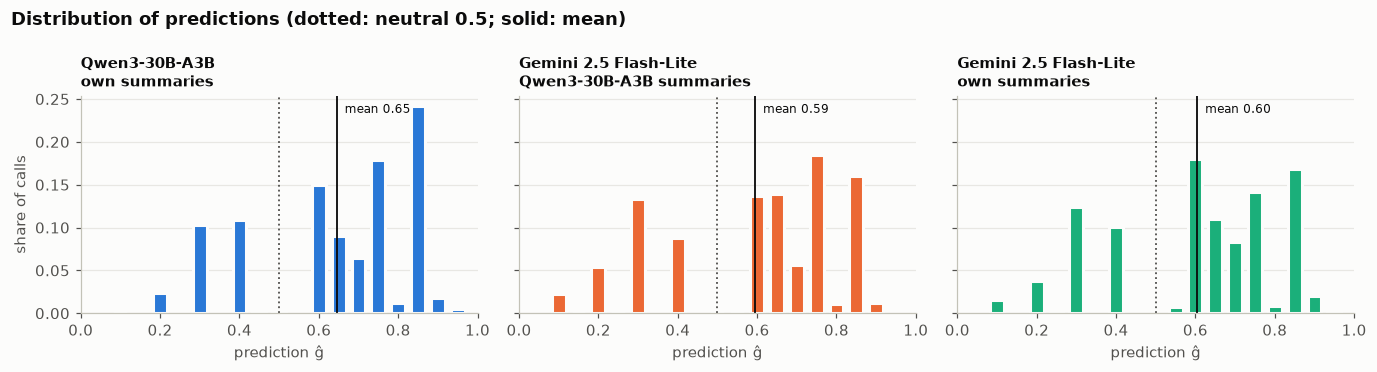

In [5]:
prow = {}
for R in RUNS:
    g = R['d']['g']
    prow[R['label']] = {'N': f'{len(g):,}', 'Mean': f'{g.mean():.3f}', 'SD': f'{g.std():.3f}',
                        'Distinct values': g.nunique(), 'Above 0.5': f'{(g > 0.5).mean():.0%}',
                        'Below 0.5': f'{(g < 0.5).mean():.0%}'}
display(pd.DataFrame(prow).T)

n = len(RUNS)
fig, axes = plt.subplots(1, n, figsize=(min(4.2 * n, 14), 3.4), sharey=True, squeeze=False)
for ax, R in zip(axes[0], RUNS):
    counts = R['d']['g'].round(2).value_counts().sort_index()
    ax.bar(counts.index, counts.values / counts.sum(), width=0.035, color=R['color'], edgecolor=SURFACE, linewidth=2)
    ax.axvline(0.5, color=INK2, ls=':', lw=1.2)
    ax.axvline(R['d']['g'].mean(), color=INK, lw=1.2)
    ax.text(R['d']['g'].mean() + 0.02, ax.get_ylim()[1] * 0.92 if ax.get_ylim()[1] > 0 else 0.3,
            f"mean {R['d']['g'].mean():.2f}", fontsize=8, color=INK)
    ax.set_xlim(0, 1)
    ax.set_title(R['label'].replace(' · ', '\n'), fontsize=10)
    ax.set_xlabel('prediction ĝ')
    ax.grid(axis='x', visible=False)
axes[0][0].set_ylabel('share of calls')
fig.suptitle('Distribution of predictions (dotted: neutral 0.5; solid: mean)', x=0.01, ha='left',
             fontsize=12, fontweight='bold')
fig.tight_layout()
plt.show()

In [6]:
# One call through every run: what each model predicted and why
common_ids = set.intersection(*[set(R['d']['transcriptid']) for R in RUNS])
ex_id = base[base['transcriptid'].isin(common_ids)].sort_values(['event_date', 'transcriptid'])['transcriptid'].iloc[0]
ex = base.set_index('transcriptid').loc[ex_id]
print(f"{ex.ticker}  event {ex.event_date:%Y-%m-%d}  |  realized return rank {ex.y:.2f}  |  surprise rank {ex.s:.2f}\n")
for R in RUNS:
    r = R['d'].set_index('transcriptid').loc[ex_id]
    try:
        reasons = '; '.join(json.loads(r.reasons))
    except Exception:
        reasons = str(r.reasons)
    print(f"{R['label']}\n    prediction {r.g:.2f}: {reasons}\n")

AYI  event 2025-10-01  |  realized return rank 0.75  |  surprise rank 0.45

Qwen3-30B-A3B · own summaries
    prediction 0.85: Strong margin expansion and sales growth above expectations; Raised guidance with clear long-term growth targets; Management tone signals resilience despite macro headwinds

Gemini 2.5 Flash-Lite · Qwen3-30B-A3B summaries
    prediction 0.75: Raised guidance for both sales and EPS signals strong future performance.; Margins expanded across segments, driven by cost actions and integration.; Management commentary indicates resilience in a tepid environment, though Q&A reveals some inventory build and tariff impacts.

Gemini 2.5 Flash-Lite · own summaries
    prediction 0.60: Results met expectations, with management confirming performance was strong and in line with guidance.; Guidance was reaffirmed, indicating management's confidence in future performance despite a tepid economic environment.; Margins expanded year-over-year, though some negative impact from ta

## 3. Main regressions, run by run (the paper's Tables 2-4)

The specifications follow the paper's tables:
1. **(1) Baseline:** `y = a + θ·s`.
2. **(2) LLM alone:** `y = a + γ·ĝ`.
3. **(3) LLM + surprise:** `y = a + γ·ĝ + θ·s`.

Coefficients use conventional OLS standard errors in parentheses, as in the paper. R² comes with its 99% bootstrap
interval in brackets: resample calls with replacement, refit, and take the 0.5th and 99.5th percentiles.

Within a run, every specification uses the same bootstrap draws. That makes the interval for
**ΔR² = R²(3) − R²(1)** a paired one, the direct test of whether the LLM adds information beyond the surprise.
The summary table comes first, then each run in full.

In [7]:
def r2(y, X):
    X1 = np.column_stack([np.ones(len(y)), X])
    e = y - X1 @ np.linalg.lstsq(X1, y, rcond=None)[0]
    return 1 - e @ e / ((y - y.mean()) @ (y - y.mean()))

def boot_r2(d, xs, idx):
    y, X = d['y'].to_numpy(float), d[xs].to_numpy(float)
    return np.array([r2(y[i], X[i]) for i in idx])

def ci(draws):
    return tuple(np.percentile(draws, [0.5, 99.5]))

def draw(n, seed=SEED):
    return np.random.default_rng(seed).integers(0, n, size=(B, n))

def fmt(v, c, dp=2):
    return f'{v:.3f} [{c[0]:.{dp}f}, {c[1]:.{dp}f}]'

LABELS = {'Intercept': 'Intercept', 'g': 'LLM prediction ĝ', 's': 'Surprise PRank(s)'}
MAIN = {'(1) Baseline': ['s'], '(2) LLM': ['g'], '(3) LLM + surprise': ['g', 's']}

def reg_table(d, specs, idx):
    # Paper-style table: coef (SE), R² [99% CI], adj. R², N, F. Also returns the fits and bootstrap draws.
    cols, fits, draws = {}, {}, {}
    for name, xs in specs.items():
        res = smf.ols('y ~ ' + ' + '.join(xs), d).fit()
        dr = boot_r2(d, xs, idx)
        col = {lab: (f'{res.params[v]:.3f} ({res.bse[v]:.3f})' if v in res.params else '') for v, lab in LABELS.items()}
        col.update({'R²': fmt(res.rsquared, ci(dr)), 'Adjusted R²': f'{res.rsquared_adj:.3f}',
                    'Observations': f'{int(res.nobs):,}', 'F statistic': f'{res.fvalue:.1f}'})
        cols[name], fits[name], draws[name] = col, res, dr
    return pd.DataFrame(cols), fits, draws

for R in RUNS:
    R['tab'], R['fits'], R['draws'] = reg_table(R['d'], MAIN, draw(len(R['d'])))
    R['r2'] = {k: f.rsquared for k, f in R['fits'].items()}
    R['ci'] = {k: ci(v) for k, v in R['draws'].items()}
    R['dr2'] = R['r2']['(3) LLM + surprise'] - R['r2']['(1) Baseline']
    R['dci'] = ci(R['draws']['(3) LLM + surprise'] - R['draws']['(1) Baseline'])

summary = pd.DataFrame({R['label']: {
    'N': f"{len(R['d']):,}",
    'Surprise only R²': fmt(R['r2']['(1) Baseline'], R['ci']['(1) Baseline']),
    'LLM alone R²': fmt(R['r2']['(2) LLM'], R['ci']['(2) LLM']),
    'LLM + surprise R²': fmt(R['r2']['(3) LLM + surprise'], R['ci']['(3) LLM + surprise']),
    'ΔR² over surprise [paired 99% CI]': fmt(R['dr2'], R['dci'], 3),
    'γ on ĝ (with s)': f"{R['fits']['(3) LLM + surprise'].params['g']:.3f}",
    'θ on s (with ĝ)': f"{R['fits']['(3) LLM + surprise'].params['s']:.3f}",
} for R in RUNS}).T
display(summary)

for R in RUNS:
    display(Markdown(f"**{R['label']}**  (dependent variable: PRank(r_abn))"))
    display(R['tab'])

,N,Surprise only R²,LLM alone R²,LLM + surprise R²,ΔR² over surprise [paired 99% CI],γ on ĝ (with s),θ on s (with ĝ)
Qwen3-30B-A3B · own summaries,"2,583","0.047 [0.03, 0.07]","0.072 [0.05, 0.10]","0.102 [0.08, 0.13]","0.055 [0.036, 0.079]",0.351,0.176
Gemini 2.5 Flash-Lite · Qwen3-30B-A3B summaries,"2,583","0.047 [0.03, 0.07]","0.079 [0.06, 0.11]","0.110 [0.08, 0.14]","0.062 [0.041, 0.089]",0.338,0.178
Gemini 2.5 Flash-Lite · own summaries,"2,585","0.047 [0.03, 0.07]","0.084 [0.06, 0.12]","0.112 [0.09, 0.15]","0.065 [0.043, 0.093]",0.363,0.172


**Qwen3-30B-A3B · own summaries**  (dependent variable: PRank(r_abn))

,(1) Baseline,(2) LLM,(3) LLM + surprise
Intercept,0.391 (0.011),0.244 (0.019),0.185 (0.020)
LLM prediction ĝ,,0.396 (0.028),0.351 (0.028)
Surprise PRank(s),0.218 (0.019),,0.176 (0.019)
R²,"0.047 [0.03, 0.07]","0.072 [0.05, 0.10]","0.102 [0.08, 0.13]"
Adjusted R²,0.047,0.071,0.101
Observations,"2,583","2,583","2,583"
F statistic,128.3,199.7,146.5


**Gemini 2.5 Flash-Lite · Qwen3-30B-A3B summaries**  (dependent variable: PRank(r_abn))

,(1) Baseline,(2) LLM,(3) LLM + surprise
Intercept,0.391 (0.011),0.277 (0.016),0.210 (0.017)
LLM prediction ĝ,,0.375 (0.025),0.338 (0.025)
Surprise PRank(s),0.218 (0.019),,0.178 (0.019)
R²,"0.047 [0.03, 0.07]","0.079 [0.06, 0.11]","0.110 [0.08, 0.14]"
Adjusted R²,0.047,0.078,0.109
Observations,"2,583","2,583","2,583"
F statistic,128.3,220.2,158.8


**Gemini 2.5 Flash-Lite · own summaries**  (dependent variable: PRank(r_abn))

,(1) Baseline,(2) LLM,(3) LLM + surprise
Intercept,0.391 (0.011),0.255 (0.017),0.195 (0.018)
LLM prediction ĝ,,0.405 (0.026),0.363 (0.026)
Surprise PRank(s),0.218 (0.019),,0.172 (0.019)
R²,"0.047 [0.03, 0.07]","0.084 [0.06, 0.12]","0.112 [0.09, 0.15]"
Adjusted R²,0.047,0.083,0.112
Observations,"2,585","2,585","2,585"
F statistic,128.4,236.2,163.4


## 4. Head to head on the same calls

Each run covers slightly different calls, so the runs are compared again on the calls **every** run scored,
using **one** set of bootstrap draws. That gives:
- a paired interval for each run's R² minus the first run's R², which says whether one model is really better;
- the Spearman rank correlation between models' predictions: do they pick up the same information?
- an **ensemble**: the average of each model's ranked prediction. If the models make different errors, the
  average should beat each one alone.

In [8]:
H2H, ENS = None, None
if len(RUNS) < 2:
    print('Only one run so far: the comparison appears once a second run has been scored.')
else:
    C = base[base['transcriptid'].isin(common_ids)].copy()
    cols = []
    for k, R in enumerate(RUNS):
        c = f'g{k}'
        C[c] = C['transcriptid'].map(R['d'].set_index('transcriptid')['g'])
        C[f'r{k}'] = C[c].rank(pct=True)
        cols.append(c)
    idx = draw(len(C))
    base_d = boot_r2(C, ['s'], idx)
    ref_d = boot_r2(C, [cols[0], 's'], idx)
    yC = C['y'].to_numpy(float)
    v_base, v_ref = r2(yC, C[['s']].to_numpy(float)), r2(yC, C[[cols[0], 's']].to_numpy(float))
    rows = {}
    for k, R in enumerate(RUNS):
        dr = boot_r2(C, [cols[k], 's'], idx)
        v = r2(yC, C[[cols[k], 's']].to_numpy(float))
        rows[R['label']] = {'LLM + surprise R²': fmt(v, ci(dr)),
                            'ΔR² over surprise': fmt(v - v_base, ci(dr - base_d), 3),
                            f'vs. {RUNS[0]["label"]}': '—' if k == 0 else fmt(v - v_ref, ci(dr - ref_d), 3)}
        R['h2h'] = (v, ci(dr))
    C['ens'] = C[[f'r{k}' for k in range(len(RUNS))]].mean(axis=1)
    ens_d = boot_r2(C, ['ens', 's'], idx)
    ens_v = r2(yC, C[['ens', 's']].to_numpy(float))
    best_k = int(np.argmax([R['h2h'][0] for R in RUNS]))
    best_d = boot_r2(C, [cols[best_k], 's'], idx)
    rows['Ensemble (mean of ranked predictions)'] = {
        'LLM + surprise R²': fmt(ens_v, ci(ens_d)),
        'ΔR² over surprise': fmt(ens_v - v_base, ci(ens_d - base_d), 3),
        f'vs. {RUNS[0]["label"]}': fmt(ens_v - RUNS[0]['h2h'][0], ci(ens_d - ref_d), 3)}
    H2H = pd.DataFrame(rows).T
    ENS = dict(v=ens_v, ci=ci(ens_d), gain=ens_v - RUNS[best_k]['h2h'][0], gain_ci=ci(ens_d - best_d),
               best=RUNS[best_k]['label'])
    print(f'{len(C):,} calls scored by all {len(RUNS)} runs. Intervals: 99%, paired (same resamples for every row).')
    display(H2H)

    corr = C[[f'r{k}' for k in range(len(RUNS))] + ['s', 'y']].corr(method='spearman')
    names = [R['label'] for R in RUNS] + ['Surprise rank', 'Return rank']
    corr.index, corr.columns = names, names
    display(Markdown('**Spearman correlation of predictions** (and with the surprise and the realized return)'))
    display(corr.round(2))

2,583 calls scored by all 3 runs. Intervals: 99%, paired (same resamples for every row).


,LLM + surprise R²,ΔR² over surprise,vs. Qwen3-30B-A3B · own summaries
Qwen3-30B-A3B · own summaries,"0.102 [0.08, 0.13]","0.055 [0.036, 0.079]",—
Gemini 2.5 Flash-Lite · Qwen3-30B-A3B summaries,"0.110 [0.08, 0.14]","0.062 [0.041, 0.089]","0.008 [-0.004, 0.019]"
Gemini 2.5 Flash-Lite · own summaries,"0.112 [0.09, 0.14]","0.065 [0.045, 0.091]","0.010 [-0.006, 0.026]"
Ensemble (mean of ranked predictions),"0.117 [0.09, 0.15]","0.069 [0.047, 0.096]","0.015 [0.005, 0.025]"


**Spearman correlation of predictions** (and with the surprise and the realized return)

,Qwen3-30B-A3B · own summaries,Gemini 2.5 Flash-Lite · Qwen3-30B-A3B summaries,Gemini 2.5 Flash-Lite · own summaries,Surprise rank,Return rank
Qwen3-30B-A3B · own summaries,1.00,0.89,0.76,0.15,0.26
Gemini 2.5 Flash-Lite · Qwen3-30B-A3B summaries,0.89,1.00,0.75,0.14,0.28
Gemini 2.5 Flash-Lite · own summaries,0.76,0.75,1.00,0.17,0.28
Surprise rank,0.15,0.14,0.17,1.00,0.22
Return rank,0.26,0.28,0.28,0.22,1.00


## 5. Side by side with the paper

The paper's numbers were typed in from its Tables 2-4 (N = 1,849). Each of our runs is placed next to the paper
row with the **same model and setup**, where the paper has one. The paper reports intervals for each R², not
for ΔR², so its ΔR² is the difference of two point estimates.

Differences to keep in mind:
- **Data:** the paper uses Benzinga for the consensus and Massive for returns. We use I/B/E/S and CRSP, on more
  calls (US, Q4 2025).
- **Table 4:** in the paper, every model scores Opus 4.5's summaries. Our "other model's summaries" runs use
  whichever model wrote them.

In [9]:
PAPER_N = 1849
PAPER_BASE = {'r2': 0.050, 'ci': (0.03, 0.08), 'theta': 0.219}
# (table, model): LLM alone (R², 99% CI), LLM + surprise (R², 99% CI), γ and θ in the joint regression
PAPER = {
    ('Table 2', 'GPT-5 nano'):            dict(llm=(0.071, (0.04, 0.10)), both=(0.107, (0.08, 0.15)), g=0.656, s=0.187),
    ('Table 2', 'Gemini 2.5 Flash-Lite'): dict(llm=(0.075, (0.05, 0.11)), both=(0.112, (0.08, 0.15)), g=0.343, s=0.190),
    ('Table 2', 'Opus 4.5'):              dict(llm=(0.109, (0.08, 0.15)), both=(0.143, (0.10, 0.18)), g=0.565, s=0.181),
    ('Table 3', 'GPT-5 nano'):            dict(llm=(0.030, (0.01, 0.05)), both=(0.073, (0.04, 0.11)), g=0.257, s=0.203),
    ('Table 3', 'Gemini 2.5 Flash-Lite'): dict(llm=(0.065, (0.04, 0.10)), both=(0.098, (0.07, 0.13)), g=0.252, s=0.180),
    ('Table 3', 'Opus 4.5'):              dict(llm=(0.093, (0.06, 0.13)), both=(0.130, (0.09, 0.18)), g=0.442, s=0.189),
    ('Table 4', 'GPT-5 nano'):            dict(llm=(0.067, (0.04, 0.10)), both=(0.106, (0.07, 0.15)), g=0.329, s=0.194),
    ('Table 4', 'Gemini 2.5 Flash-Lite'): dict(llm=(0.075, (0.05, 0.11)), both=(0.112, (0.08, 0.15)), g=0.264, s=0.189),
    ('Table 4', 'Opus 4.5'):              dict(llm=(0.093, (0.06, 0.13)), both=(0.130, (0.09, 0.18)), g=0.442, s=0.189),
}
TABLE_SETUP = {'Table 2': 'full transcripts', 'Table 3': 'own summaries', 'Table 4': 'Opus 4.5 summaries'}

cmp_rows = {}
for R in RUNS:
    p = PAPER.get((R['paper_table'], R['paper_model']))
    j = R['fits']['(3) LLM + surprise']
    cmp_rows[R['label']] = {
        'Paper setup': f"{R['paper_table']} ({TABLE_SETUP[R['paper_table']]})" if R['paper_table'] else '—',
        'N': f"{len(R['d']):,}",
        'LLM alone R²': fmt(R['r2']['(2) LLM'], R['ci']['(2) LLM']),
        'LLM + surprise R²': fmt(R['r2']['(3) LLM + surprise'], R['ci']['(3) LLM + surprise']),
        'ΔR²': f"{R['dr2']:.3f}",
        'γ, θ (joint)': f"{j.params['g']:.3f}, {j.params['s']:.3f}",
        'Paper, same model & setup: LLM + surprise R²': fmt(*p['both']) if p else '—',
        'Paper ΔR²': f"{p['both'][0] - PAPER_BASE['r2']:.3f}" if p else '—',
        'Paper γ, θ': f"{p['g']:.3f}, {p['s']:.3f}" if p else '—',
    }
display(Markdown('**Our runs, each next to its paper counterpart**'))
display(pd.DataFrame(cmp_rows).T)

ref = pd.DataFrame({f'{m} ({t})': {'LLM alone R²': fmt(*p['llm']), 'LLM + surprise R²': fmt(*p['both']),
                                   'ΔR²': f"{p['both'][0] - PAPER_BASE['r2']:.3f}", 'γ': p['g'], 'θ': p['s']}
                    for (t, m), p in PAPER.items()}).T
display(Markdown(f"**The paper's rows for reference** (surprise only: {fmt(PAPER_BASE['r2'], PAPER_BASE['ci'])}, "
                 f"θ = {PAPER_BASE['theta']})"))
display(ref)

**Our runs, each next to its paper counterpart**

,Paper setup,N,LLM alone R²,LLM + surprise R²,ΔR²,"γ, θ (joint)","Paper, same model & setup: LLM + surprise R²",Paper ΔR²,"Paper γ, θ"
Qwen3-30B-A3B · own summaries,Table 3 (own summaries),"2,583","0.072 [0.05, 0.10]","0.102 [0.08, 0.13]",0.055,"0.351, 0.176",—,—,—
Gemini 2.5 Flash-Lite · Qwen3-30B-A3B summaries,Table 4 (Opus 4.5 summaries),"2,583","0.079 [0.06, 0.11]","0.110 [0.08, 0.14]",0.062,"0.338, 0.178","0.112 [0.08, 0.15]",0.062,"0.264, 0.189"
Gemini 2.5 Flash-Lite · own summaries,Table 3 (own summaries),"2,585","0.084 [0.06, 0.12]","0.112 [0.09, 0.15]",0.065,"0.363, 0.172","0.098 [0.07, 0.13]",0.048,"0.252, 0.180"


**The paper's rows for reference** (surprise only: 0.050 [0.03, 0.08], θ = 0.219)

,LLM alone R²,LLM + surprise R²,ΔR²,γ,θ
GPT-5 nano (Table 2),"0.071 [0.04, 0.10]","0.107 [0.08, 0.15]",0.057,0.656,0.187
Gemini 2.5 Flash-Lite (Table 2),"0.075 [0.05, 0.11]","0.112 [0.08, 0.15]",0.062,0.343,0.19
Opus 4.5 (Table 2),"0.109 [0.08, 0.15]","0.143 [0.10, 0.18]",0.093,0.565,0.181
GPT-5 nano (Table 3),"0.030 [0.01, 0.05]","0.073 [0.04, 0.11]",0.023,0.257,0.203
Gemini 2.5 Flash-Lite (Table 3),"0.065 [0.04, 0.10]","0.098 [0.07, 0.13]",0.048,0.252,0.18
Opus 4.5 (Table 3),"0.093 [0.06, 0.13]","0.130 [0.09, 0.18]",0.080,0.442,0.189
GPT-5 nano (Table 4),"0.067 [0.04, 0.10]","0.106 [0.07, 0.15]",0.056,0.329,0.194
Gemini 2.5 Flash-Lite (Table 4),"0.075 [0.05, 0.11]","0.112 [0.08, 0.15]",0.062,0.264,0.189
Opus 4.5 (Table 4),"0.093 [0.06, 0.13]","0.130 [0.09, 0.18]",0.080,0.442,0.189


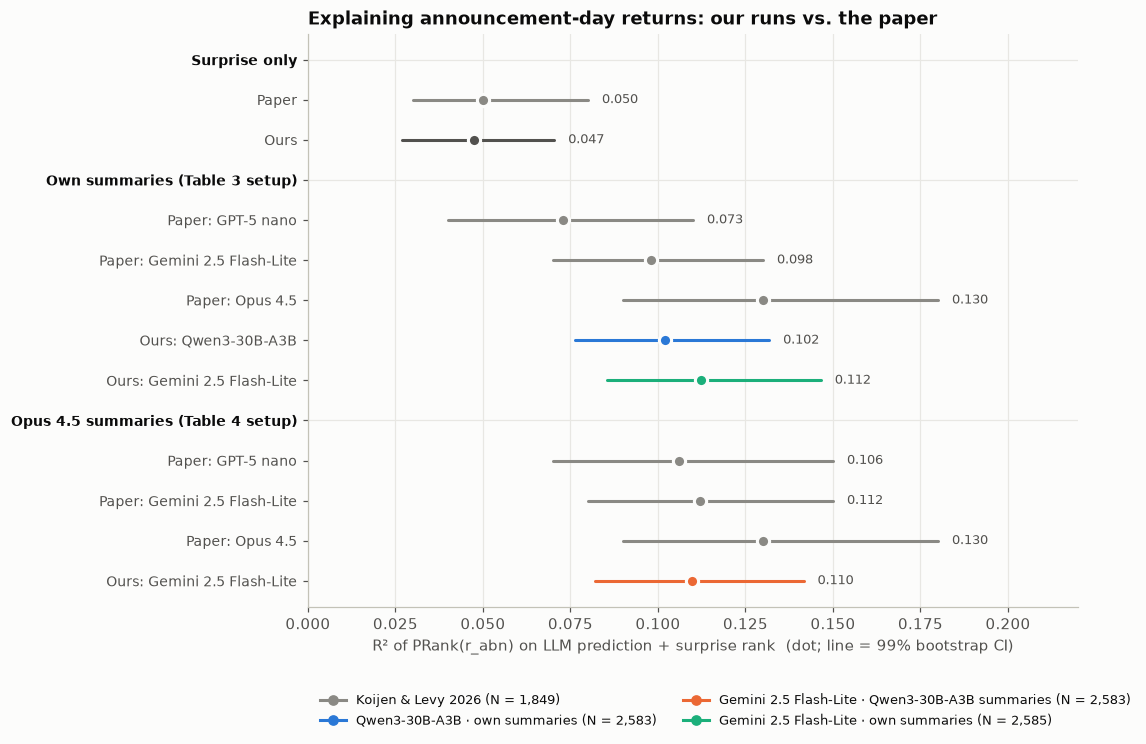

In [10]:
# Dot-and-interval chart: LLM + surprise R², grouped by setup; paper rows in grey, our runs in their run color
items = [('header', 'Surprise only'),
         ('row', 'Paper', PAPER_BASE['r2'], PAPER_BASE['ci'], NEUTRAL),
         ('row', 'Ours', RUNS[0]['r2']['(1) Baseline'], RUNS[0]['ci']['(1) Baseline'], INK2)]
for t in ['Table 3', 'Table 2', 'Table 4']:
    mine = [R for R in RUNS if R['paper_table'] == t]
    if not mine:
        continue
    items.append(('header', f'{TABLE_SETUP[t].capitalize()} ({t} setup)'))
    items += [('row', f'Paper: {m}', *PAPER[(t, m)]['both'], NEUTRAL) for m in PAPER_MODELS]
    items += [('row', f"Ours: {R['label'].split(' · ')[0]}", R['r2']['(3) LLM + surprise'],
               R['ci']['(3) LLM + surprise'], R['color']) for R in mine]
other = [R for R in RUNS if R['paper_table'] is None]
if other:
    items.append(('header', 'No paper counterpart'))
    items += [('row', f"Ours: {R['label']}", R['r2']['(3) LLM + surprise'], R['ci']['(3) LLM + surprise'], R['color'])
              for R in other]

items = items[::-1]   # first item on top
fig, ax = plt.subplots(figsize=(10, 0.36 * len(items) + 1.4 + 0.22 * (len(RUNS) + 1) / 2))
labels = []
for i, it in enumerate(items):
    if it[0] == 'header':
        labels.append(it[1])
        ax.axhline(i, color='#e8e7e3', lw=0.8)
        continue
    _, lab, v, (lo, hi), c = it
    ax.plot([lo, hi], [i, i], color=c, lw=2, solid_capstyle='round')
    ax.plot(v, i, 'o', color=c, markersize=8, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.text(hi + 0.004, i, f'{v:.3f}', va='center', fontsize=8.5, color=INK2)
    labels.append('    ' + lab)
ax.set_yticks(range(len(items)), labels, fontsize=9)
for tick, it in zip(ax.get_yticklabels(), items):
    if it[0] == 'header':
        tick.set_fontweight('bold')
        tick.set_color(INK)
ax.set_xlim(0, max(0.22, max(it[3][1] for it in items if it[0] == 'row') + 0.03))
ax.set_xlabel('R² of PRank(r_abn) on LLM prediction + surprise rank  (dot; line = 99% bootstrap CI)')
ax.grid(axis='y', visible=False)
ax.plot([], [], 'o-', color=NEUTRAL, label=f'Koijen & Levy 2026 (N = {PAPER_N:,})')
for R in RUNS:
    ax.plot([], [], 'o-', color=R['color'], label=f"{R['label']} (N = {len(R['d']):,})")
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.13), ncol=2, fontsize=8.5)
ax.set_title('Explaining announcement-day returns: our runs vs. the paper')
fig.tight_layout()
plt.show()

## 6. Early vs. late announcements (the paper's Table 5)

The paper splits the quarter at the median event date. The early half is its training set for prompt
optimization, and the late half is held out. It finds the late half no harder. Our split is the same for every
run: early means `event_date <= median`, with the median taken over all in-sample calls.

The paper's Table 5 numbers come from Opus 4.5 summaries, scored by each model.

In [11]:
MED = base['event_date'].median()
PAPER_T5 = {'GPT-5 nano':            {'Early': (0.066, (0.04, 0.11)), 'Late': (0.085, (0.05, 0.14))},
            'Gemini 2.5 Flash-Lite': {'Early': (0.093, (0.06, 0.14)), 'Late': (0.105, (0.06, 0.16))},
            'Opus 4.5':              {'Early': (0.118, (0.07, 0.18)), 'Late': (0.141, (0.09, 0.20))}}
PAPER_T5_N = {'Early': 1032, 'Late': 817}
t5 = {}
for R in RUNS:
    R['halves'] = {}
    for h, d in [('Early', R['d'][R['d'].event_date <= MED]), ('Late', R['d'][R['d'].event_date > MED])]:
        _, fits, dr = reg_table(d, {'base': ['s'], 'both': ['g', 's']}, draw(len(d)))
        R['halves'][h] = dict(base=fits['base'].rsquared, both=fits['both'].rsquared, both_ci=ci(dr['both']))
        t5[f"{R['label']}: {h}"] = {'N': f'{len(d):,}', 'Surprise only R²': fmt(fits['base'].rsquared, ci(dr['base'])),
                                    'LLM + surprise R²': fmt(fits['both'].rsquared, ci(dr['both'])),
                                    'ΔR²': f"{fits['both'].rsquared - fits['base'].rsquared:.3f}"}
for m, p in PAPER_T5.items():
    for h in ('Early', 'Late'):
        t5[f'Paper, {m} on Opus summaries: {h}'] = {'N': f'{PAPER_T5_N[h]:,}', 'Surprise only R²': '',
                                                     'LLM + surprise R²': fmt(*p[h]), 'ΔR²': ''}
print(f'Median event date: {MED:%Y-%m-%d}')
display(pd.DataFrame(t5).T)

Median event date: 2025-11-05


,N,Surprise only R²,LLM + surprise R²,ΔR²
Qwen3-30B-A3B · own summaries: Early,"1,442","0.058 [0.03, 0.09]","0.109 [0.07, 0.15]",0.051
Qwen3-30B-A3B · own summaries: Late,"1,141","0.039 [0.02, 0.07]","0.096 [0.06, 0.15]",0.057
Gemini 2.5 Flash-Lite · Qwen3-30B-A3B summaries: Early,"1,442","0.058 [0.03, 0.09]","0.119 [0.08, 0.16]",0.061
Gemini 2.5 Flash-Lite · Qwen3-30B-A3B summaries: Late,"1,141","0.039 [0.02, 0.07]","0.101 [0.07, 0.15]",0.062
Gemini 2.5 Flash-Lite · own summaries: Early,"1,444","0.058 [0.03, 0.09]","0.117 [0.08, 0.16]",0.059
Gemini 2.5 Flash-Lite · own summaries: Late,"1,141","0.039 [0.02, 0.07]","0.110 [0.07, 0.15]",0.071
"Paper, GPT-5 nano on Opus summaries: Early","1,032",,"0.066 [0.04, 0.11]",
"Paper, GPT-5 nano on Opus summaries: Late",817,,"0.085 [0.05, 0.14]",
"Paper, Gemini 2.5 Flash-Lite on Opus summaries: Early","1,032",,"0.093 [0.06, 0.14]",
"Paper, Gemini 2.5 Flash-Lite on Opus summaries: Late",817,,"0.105 [0.06, 0.16]",


## 7. Calibration: does each model think every call is good news?

Events are sorted into quintiles of each run's prediction. Ties are broken at random with a fixed seed, because
predictions take few distinct values. For each quintile the left chart plots the **average prediction** against
the **average realized return rank**:
- **On the dotted diagonal**, the prediction would be a calibrated rank.
- **A rising curve right of the diagonal** means the model ranks well but is optimistic. That is the paper's
  "good is priced in" finding, which its GEPA optimization learned to correct.

The grey dashed line is the surprise rank, for reference. The right chart shows the day-0 abnormal return of the
top quintile minus the bottom quintile. This is the announcement reaction itself, so it is not tradable.

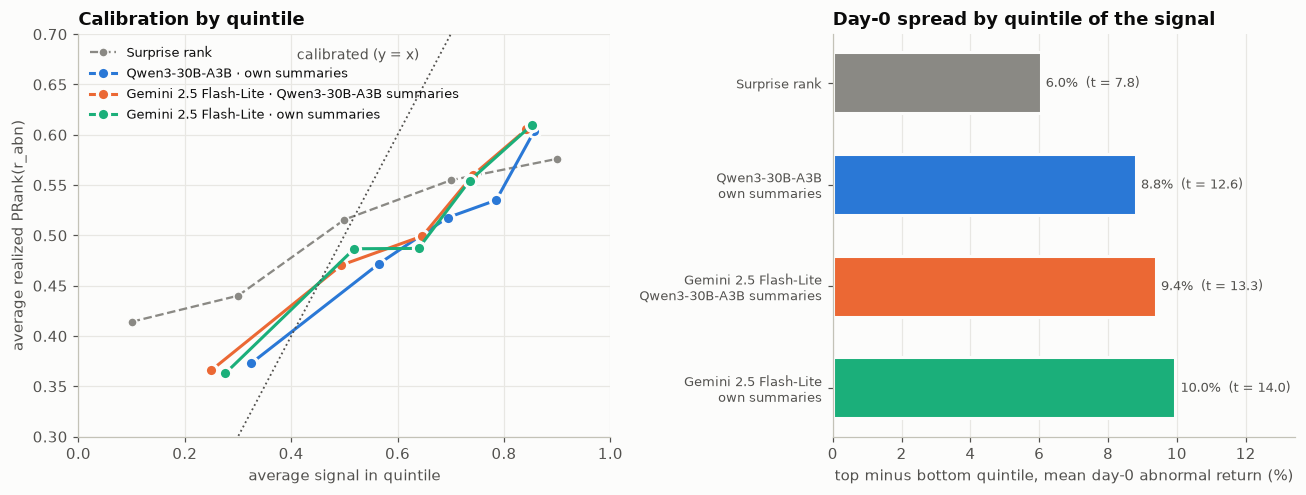

,Mean prediction,Mean realized rank,Bias,Share above 0.5,Q5 - Q1 day-0 return,t (calls independent)
Qwen3-30B-A3B · own summaries,0.645,0.500,+0.145,76%,8.81%,12.6
Gemini 2.5 Flash-Lite · Qwen3-30B-A3B summaries,0.595,0.500,+0.095,70%,9.39%,13.3
Gemini 2.5 Flash-Lite · own summaries,0.604,0.500,+0.104,72%,9.96%,14.0


In [12]:
def quintile(x):
    r = x.sample(frac=1, random_state=SEED).rank(method='first').reindex(x.index)
    return pd.qcut(r, 5, labels=[1, 2, 3, 4, 5]).astype(int)

def spread(d, q):
    top, bot = d.loc[q == 5, 'r_abn'], d.loc[q == 1, 'r_abn']
    return top.mean() - bot.mean(), (top.mean() - bot.mean()) / np.sqrt(top.var() / len(top) + bot.var() / len(bot))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1.15, 1]})
qs = quintile(base['s'])
cs = base.groupby(qs).agg(signal=('s', 'mean'), realized=('y', 'mean'))
a1.plot(cs.signal, cs.realized, '--o', color=NEUTRAL, lw=1.5, markersize=6, markeredgecolor=SURFACE, label='Surprise rank')
bars = [('Surprise rank', *spread(base, qs), NEUTRAL)]
for R in RUNS:
    d = R['d']
    q = quintile(d['g'])
    c = d.groupby(q).agg(signal=('g', 'mean'), realized=('y', 'mean'))
    a1.plot(c.signal, c.realized, '-o', color=R['color'], markersize=8, markeredgecolor=SURFACE, markeredgewidth=2,
            label=R['label'])
    sp, t = spread(d, q)
    R['bias'] = dict(mean=d['g'].mean(), realized=d['y'].mean(), above=(d['g'] > 0.5).mean(), spread=sp, t=t)
    bars.append((R['label'], sp, t, R['color']))
a1.plot([0, 1], [0, 1], ':', color=INK2, lw=1.2)
a1.text(0.64, 0.675, 'calibrated (y = x)', color=INK2, fontsize=9, ha='right')
a1.set(xlim=(0, 1), ylim=(0.3, 0.7), xlabel='average signal in quintile', ylabel='average realized PRank(r_abn)')
a1.legend(loc='upper left', fontsize=8.5)
a1.set_title('Calibration by quintile')

bars = bars[::-1]
a2.barh(range(len(bars)), [b[1] * 100 for b in bars], height=0.6, color=[b[3] for b in bars], edgecolor=SURFACE, linewidth=2)
for i, (lab, sp, t, _) in enumerate(bars):
    a2.text(sp * 100 + 0.15, i, f'{sp * 100:.1f}%  (t = {t:.1f})', va='center', fontsize=8.5, color=INK2)
a2.set_yticks(range(len(bars)), [b[0].replace(' · ', '\n') for b in bars], fontsize=8.5)
a2.set_xlim(0, max(b[1] for b in bars) * 100 * 1.35)
a2.set_xlabel('top minus bottom quintile, mean day-0 abnormal return (%)')
a2.grid(axis='y', visible=False)
a2.set_title('Day-0 spread by quintile of the signal')
fig.tight_layout()
plt.show()

display(pd.DataFrame({R['label']: {
    'Mean prediction': f"{R['bias']['mean']:.3f}", 'Mean realized rank': f"{R['bias']['realized']:.3f}",
    'Bias': f"{R['bias']['mean'] - R['bias']['realized']:+.3f}", 'Share above 0.5': f"{R['bias']['above']:.0%}",
    'Q5 - Q1 day-0 return': f"{R['bias']['spread'] * 100:.2f}%", 't (calls independent)': f"{R['bias']['t']:.1f}",
} for R in RUNS}).T)

## 8. Robustness

For each run:
- **Clustered standard errors:** calls on the same event date share market and industry shocks, so t-stats are
  recomputed with standard errors clustered by event date.
- **Ranked prediction:** `PRank(ĝ)` replaces `ĝ`. This removes each model's own scale and bias.
- **Transcript timing:** the result is rerun on calls whose transcript was out by the event-day close.

In [13]:
rob = {}
for R in RUNS:
    d = R['d']
    checks = [('Main: ĝ + s', d, ['g', 's']), ('PRank(ĝ) + s', d, ['g_rank', 's'])]
    if 'transcript_by_event_close' in d:
        checks.append(('Transcript out by event-day close', d[d['transcript_by_event_close'] == True], ['g', 's']))
    for name, x, xs in checks:
        f = 'y ~ ' + ' + '.join(xs)
        res = smf.ols(f, x).fit()
        cl = smf.ols(f, x).fit(cov_type='cluster', cov_kwds={'groups': x['date']})
        rob[(R['label'], name)] = {'N': f'{int(res.nobs):,}', 'R²': f'{res.rsquared:.3f}',
                                   'ΔR² over s': f"{res.rsquared - smf.ols('y ~ s', x).fit().rsquared:.3f}",
                                   'LLM coef': f'{res.params[xs[0]]:.3f}', 't (OLS)': f'{res.tvalues[xs[0]]:.1f}',
                                   't (clustered)': f'{cl.tvalues[xs[0]]:.1f}', 's coef': f"{res.params['s']:.3f}",
                                   's t (clustered)': f"{cl.tvalues['s']:.1f}"}
display(pd.DataFrame(rob).T)
print(f"{base['date'].nunique()} event-date clusters")

N     R² ΔR² over s LLM coef t (OLS) t (clustered) s coef s t (clustered)
Qwen3-30B-A3B · own summaries                   Main: ĝ + s                        2,583  0.102      0.055    0.351    12.5          14.7  0.176            10.2
                                                PRank(ĝ) + s                       2,583  0.102      0.054    0.239    12.5          13.8  0.181            10.4
                                                Transcript out by event-day close  2,347  0.104      0.058    0.364    12.3          14.1  0.178             8.2
Gemini 2.5 Flash-Lite · Qwen3-30B-A3B summaries Main: ĝ + s                        2,583  0.110      0.062    0.338    13.4          16.4  0.178            10.8
                                                PRank(ĝ) + s                       2,583  0.109      0.062    0.254    13.4          15.9  0.181            10.6
                                                Transcript out by event-day close  2,347  0.114      0.068    0.356    13.4          14.4  0.179             8.6
Gemini 2.5 Flash-Lite · own summaries           Main: ĝ + s                        2,585  0.112      0.065    0.363    13.8          13.7  0.172             9.7
                                                PRank(ĝ) + s                       2,585  0.110      0.063    0.257    13.5          12.4  0.175             9.6
                                                Transcript out by event-day close  2,348  0.116      0.070    0.377    13.6          13.0  0.174             8.1

53 event-date clusters


## 9. Takeaways

The bullets below are generated from the results above, so they update when runs are added.

In [14]:
L = []
b0 = RUNS[0]
L.append(f"- **Baseline.** The surprise alone explains R² = {fmt(b0['r2']['(1) Baseline'], b0['ci']['(1) Baseline'])} "
         f"of the return rank (paper: {fmt(PAPER_BASE['r2'], PAPER_BASE['ci'])}).")
for R in RUNS:
    p = PAPER.get((R['paper_table'], R['paper_model']))
    if p:
        ptxt = f" The paper's {R['paper_model']} in the same setup ({R['paper_table']}) gets {p['both'][0]:.3f}."
    elif R['paper_table']:
        ptxt = (f" Closest paper setup: {R['paper_table']} ({TABLE_SETUP[R['paper_table']]}), where the paper's "
                f"models get {min(PAPER[(R['paper_table'], m)]['both'][0] for m in PAPER_MODELS):.3f}-"
                f"{max(PAPER[(R['paper_table'], m)]['both'][0] for m in PAPER_MODELS):.3f}.")
    else:
        ptxt = ''
    sig = 'clearly above 0' if R['dci'][0] > 0 else 'not distinguishable from 0'
    L.append(f"- **{R['label']}.** LLM + surprise R² = {fmt(R['r2']['(3) LLM + surprise'], R['ci']['(3) LLM + surprise'])}. "
             f"The gain over the surprise is ΔR² = {R['dr2']:.3f} [{R['dci'][0]:.3f}, {R['dci'][1]:.3f}], "
             f"{sig}.{ptxt} Mean prediction {R['bias']['mean']:.2f} (bias {R['bias']['mean'] - R['bias']['realized']:+.2f}). "
             f"Early/late: {R['halves']['Early']['both']:.3f} / {R['halves']['Late']['both']:.3f}.")
if H2H is not None:
    ranked = sorted(RUNS, key=lambda R: -R['h2h'][0])
    L.append(f"- **Head to head** on {len(common_ids):,} common calls: "
             + ', '.join(f"{R['label']} {R['h2h'][0]:.3f}" for R in ranked)
             + ". The paired differences in section 4 show which gaps are real: a difference whose interval "
               "includes 0 is within noise.")
    L.append(f"- **Ensemble.** Averaging the ranked predictions gives {fmt(ENS['v'], ENS['ci'])}, "
             f"{ENS['gain']:+.3f} vs. the best single run ({ENS['best']}), 99% CI "
             f"[{ENS['gain_ci'][0]:+.3f}, {ENS['gain_ci'][1]:+.3f}]"
             + ('. The models carry partly different information.' if ENS['gain_ci'][0] > 0 else '.'))
display(Markdown('\n'.join(L)))

- **Baseline.** The surprise alone explains R² = 0.047 [0.03, 0.07] of the return rank (paper: 0.050 [0.03, 0.08]).
- **Qwen3-30B-A3B · own summaries.** LLM + surprise R² = 0.102 [0.08, 0.13]. The gain over the surprise is ΔR² = 0.055 [0.036, 0.079], clearly above 0. Closest paper setup: Table 3 (own summaries), where the paper's models get 0.073-0.130. Mean prediction 0.65 (bias +0.15). Early/late: 0.109 / 0.096.
- **Gemini 2.5 Flash-Lite · Qwen3-30B-A3B summaries.** LLM + surprise R² = 0.110 [0.08, 0.14]. The gain over the surprise is ΔR² = 0.062 [0.041, 0.089], clearly above 0. The paper's Gemini 2.5 Flash-Lite in the same setup (Table 4) gets 0.112. Mean prediction 0.59 (bias +0.09). Early/late: 0.119 / 0.101.
- **Gemini 2.5 Flash-Lite · own summaries.** LLM + surprise R² = 0.112 [0.09, 0.15]. The gain over the surprise is ΔR² = 0.065 [0.043, 0.093], clearly above 0. The paper's Gemini 2.5 Flash-Lite in the same setup (Table 3) gets 0.098. Mean prediction 0.60 (bias +0.10). Early/late: 0.117 / 0.110.
- **Head to head** on 2,583 common calls: Gemini 2.5 Flash-Lite · own summaries 0.112, Gemini 2.5 Flash-Lite · Qwen3-30B-A3B summaries 0.110, Qwen3-30B-A3B · own summaries 0.102. The paired differences in section 4 show which gaps are real: a difference whose interval includes 0 is within noise.
- **Ensemble.** Averaging the ranked predictions gives 0.117 [0.09, 0.15], +0.004 vs. the best single run (Gemini 2.5 Flash-Lite · own summaries), 99% CI [-0.008, +0.017].

**Caveats (methodology differences from the paper):**
- **What the model sees.**
  - The paper says it feeds the model "the earnings numbers as well as the earnings call transcript" (p. 2).
  - Runs labelled "+ EPS numbers" get reported EPS, consensus and surprise (I/B/E/S) in the prompt. The other
    runs see only the text, so they can judge "vs. expectations" only from what management says.
  - A model that sees the surprise may partly copy it. Compare ΔR², not just R², across the two prompt variants.
- **Anonymization is incomplete.** Section 2 shows, for each summarizer, how often years and company names
  survive. Look-ahead risk stays low as long as every model was trained before October 2025.
- **Real time vs. after the fact.** The paper scored calls live, as transcripts arrived. We scored after the
  quarter, which is fine for models trained before the sample.
- **Data.** I/B/E/S and CRSP here, Benzinga and Massive in the paper, with more calls here. The Qwen run was
  scored on an earlier pipeline build, so it covers slightly fewer of the current in-sample calls.

**Next steps:**
1. Score more models and setups (`LLM_README.md` section 9). Each new run appears here automatically.
2. Post-announcement drift: test the best run's ĝ (or the ensemble) as a signal for 1-, 4- and 12-week CARs
   with `signals/long_short.py`. This is the tradable question.
3. By industry (FF12), reusing the SIC cache from `table1.ipynb`.